<a href="https://colab.research.google.com/github/rlacey2468/Machine_Learning_Class_Projects/blob/main/CS536_Project2_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 2 — Flower Classification Using Logistic Regression

**Name:** Rachel Lacey

**Selected classes:** Iris-setosa (0) and Iris-versicolor (1)  
**Input features:** Petal length and petal width (cm)

# Gradient Equations


1. Linear Model

The linear score for each training sample is calculated as:

$$
z_i = w_0 + w_1x_{i1} + w_2x_{i2}
$$


(w_0) is the bias weight.

(w_1) and (w_2) are the feature weights.

(x_i1) and (x_i2) are the standardized petal length and petal width.


2. Sigmoid Function


$$
\hat{y}_i = \frac{1}{1 + e^{-z_i}}
$$

3. Binary Cross-Entropy Loss

$$
J(\mathbf{w}) = -\frac{1}{m}\sum_{i=1}^{m}
\left[
y_i\ln(\hat{y}_i) +
(1-y_i)\ln(1-\hat{y}_i)
\right]
$$

where (m) is the number of training samples, (y_i) is the true label, and hat y_i is the predicted probability.

4. Gradient Calculation

The gradient of the loss function with respect to each weight is:

$$
\frac{\partial J}{\partial w_j}
=
\frac{1}{m}\sum_{i=1}^{m}
(\hat{y}_i-y_i)x_{ij}
$$

Bias weight gradient:

$$
\frac{\partial J}{\partial w_0}
=
\frac{1}{m}\sum_{i=1}^{m}
(\hat{y}_i-y_i)
$$

5. Gradient Descent Update

$$
w_j \leftarrow w_j -
\alpha\frac{\partial J}{\partial w_j}
$$

#Summary


The logistic regression model achieved 100% training accuracy and 100% testing accuracy on the selected Iris dataset. This indicates that the model successfully classified the Iris-setosa and Iris-versicolor flowers using petal length and petal width.

The training accuracy plot demonstrates the model's learning progress over 1,000 epochs. The final trained weights were (w_0 = 0.417202), (w_1 = 2.835236), and (w_2 = 2.839840).

These results show that the two selected features provide strong separation between the two flower classes, allowing logistic regression to classify the observations accurately.

### 1. Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### 2. Load the UCI Iris dataset

In [ ]:
# Load the Iris dataset from the UCI repository.
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/iris/iris.data"
)

columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width",
    "species"
]

df = pd.read_csv(url, header=None, names=columns)

# Remove blank rows, for less errors in training
df = df.dropna()

print("Original dataset shape:", df.shape)
print("\nOriginal class distribution:")
print(df["species"].value_counts())

Original dataset shape: (150, 5)

Original class distribution:
species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


### 3. Select two classes and two input features

In [ ]:
# Selecting Iris-setosa and Iris-versicolor.
selected_classes = ["Iris-setosa", "Iris-versicolor"]
data = df[df["species"].isin(selected_classes)].copy()

# Using petal length and petal width as the two input features.
feature_names = ["petal_length", "petal_width"]
X = data[feature_names].to_numpy(dtype=float)

# Encoding output: setosa = 0, versicolor = 1.
y = (data["species"] == "Iris-versicolor").to_numpy(dtype=float)

assert X.shape == (100, 2)
assert len(y) == 100

### 4. Plot input features and output-class distribution

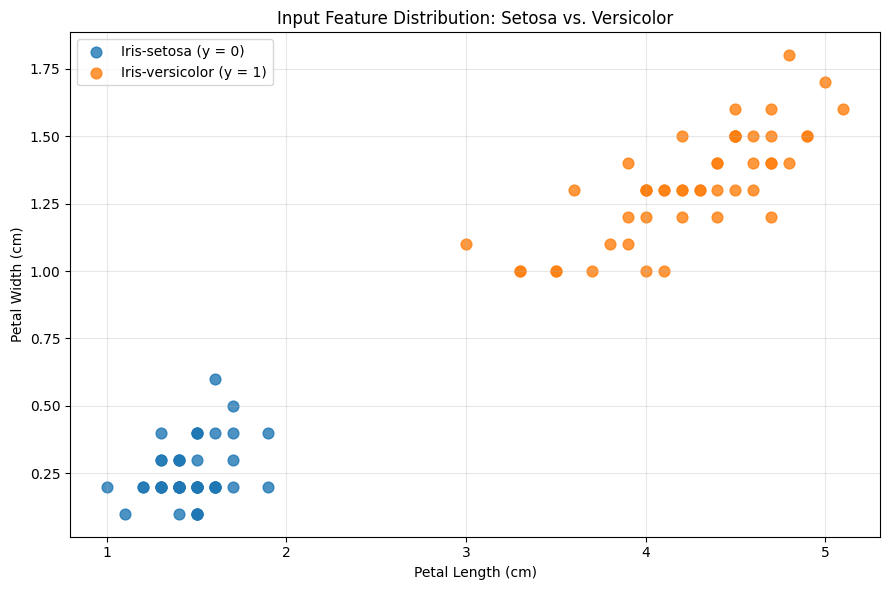

In [ ]:
# Each point is a flower and color indicates the output class.
plt.figure(figsize=(9, 6))

plt.scatter(
    X[y == 0, 0], X[y == 0, 1],
    label="Iris-setosa (y = 0)", alpha=0.8, s=60
)
plt.scatter(
    X[y == 1, 0], X[y == 1, 1],
    label="Iris-versicolor (y = 1)", alpha=0.8, s=60
)

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Input Feature Distribution: Setosa vs. Versicolor")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 5. Random stratified 80:20 train/test split

In [ ]:
# Split each class separately to preserve a 50:50 class balance.
rng = np.random.default_rng(42) #for reproducibility
train_indices = []
test_indices = []

for class_label in [0.0, 1.0]:
    class_indices = np.where(y == class_label)[0]
    class_indices = rng.permutation(class_indices)
    split_point = int(0.8 * len(class_indices))
    train_indices.extend(class_indices[:split_point])
    test_indices.extend(class_indices[split_point:])

# Shuffling combined indices without changing the split membership.
train_indices = rng.permutation(train_indices)
test_indices = rng.permutation(test_indices)

X_train = X[train_indices]
y_train = y[train_indices]
X_test = X[test_indices]
y_test = y[test_indices]

# Prints for Debugging
print("Total samples:", len(X))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print(f"Training percentage: {100 * len(X_train) / len(X):.1f}%")
print(f"Testing percentage: {100 * len(X_test) / len(X):.1f}%")

print("\nTraining class distribution:")
print("Iris-setosa (0):", int(np.sum(y_train == 0)))
print("Iris-versicolor (1):", int(np.sum(y_train == 1)))

print("\nTesting class distribution:")
print("Iris-setosa (0):", int(np.sum(y_test == 0)))
print("Iris-versicolor (1):", int(np.sum(y_test == 1)))

assert len(X_train) == 80 and len(X_test) == 20
assert np.sum(y_train == 0) == 40 and np.sum(y_train == 1) == 40
assert np.sum(y_test == 0) == 10 and np.sum(y_test == 1) == 10

Total samples: 100
Training samples: 80
Testing samples: 20
Training percentage: 80.0%
Testing percentage: 20.0%

Training class distribution:
Iris-setosa (0): 40
Iris-versicolor (1): 40

Testing class distribution:
Iris-setosa (0): 10
Iris-versicolor (1): 10


### 6. Standardize the features

In [ ]:
# Using since it made gradient descent easier in last project
# Use training-set statistics only to avoid test-set data leakage.
feature_mean = X_train.mean(axis=0)
feature_std = X_train.std(axis=0)
feature_std[feature_std == 0] = 1.0

X_train_scaled = (X_train - feature_mean) / feature_std
X_test_scaled = (X_test - feature_mean) / feature_std

# Add a column of ones for the intercept/bias parameter.
X_train_bias = np.column_stack(
    (np.ones(len(X_train_scaled)), X_train_scaled)
)
X_test_bias = np.column_stack(
    (np.ones(len(X_test_scaled)), X_test_scaled)
)

print("Training feature means:", feature_mean)
print("Training feature standard deviations:", feature_std)

Training feature means: [2.89875 0.81   ]
Training feature standard deviations: [1.45004256 0.57087652]


### 7. Define logistic regression functions from scratch

In [ ]:
#sigmoid function
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))


def predict_probability(X, weights):
    # Probability that a sample belongs to class 1.
    return sigmoid(X @ weights)


def binary_cross_entropy(X, y, weights):
    # Average binary cross-entropy loss.
    probabilities = predict_probability(X, weights)
    epsilon = 1e-12
    probabilities = np.clip(probabilities, epsilon, 1 - epsilon)
    return -np.mean(
        y * np.log(probabilities)
        + (1 - y) * np.log(1 - probabilities)
    )


def predict_class(X, weights):
    # probability at 0.5.
    return (predict_probability(X, weights) >= 0.5).astype(int)


def calculate_accuracy(X, y, weights):
    predictions = predict_class(X, weights)
    return np.mean(predictions == y) * 100

### 8. Train using gradient descent

In [ ]:
learning_rate = 0.1
epochs = 1000
m = len(y_train)

# Parameters: bias, petal-length weight, petal-width weight.
weights = np.zeros(X_train_bias.shape[1])
training_accuracies = []

for epoch in range(epochs):
    # Forward pass: predicted probabilities.
    probabilities = predict_probability(X_train_bias, weights)

    # Gradient of binary cross-entropy loss:
    # grad = X^T (predicted_probability - actual_label) / m
    gradient = (X_train_bias.T @ (probabilities - y_train)) / m

    # Gradient descent update.
    weights = weights - learning_rate * gradient

    # Record training metrics after the update.
    training_accuracies.append(
        calculate_accuracy(X_train_bias, y_train, weights)
    )

#prints for debuging
print("Training complete.")
print(f"Final training accuracy: {training_accuracies[-1]:.2f}%")
print("Final weights:", weights)

Training complete.
Final training accuracy: 100.00%
Final weights: [0.41720242 2.83523591 2.8398398 ]


### 9. Plot training accuracy versus epochs

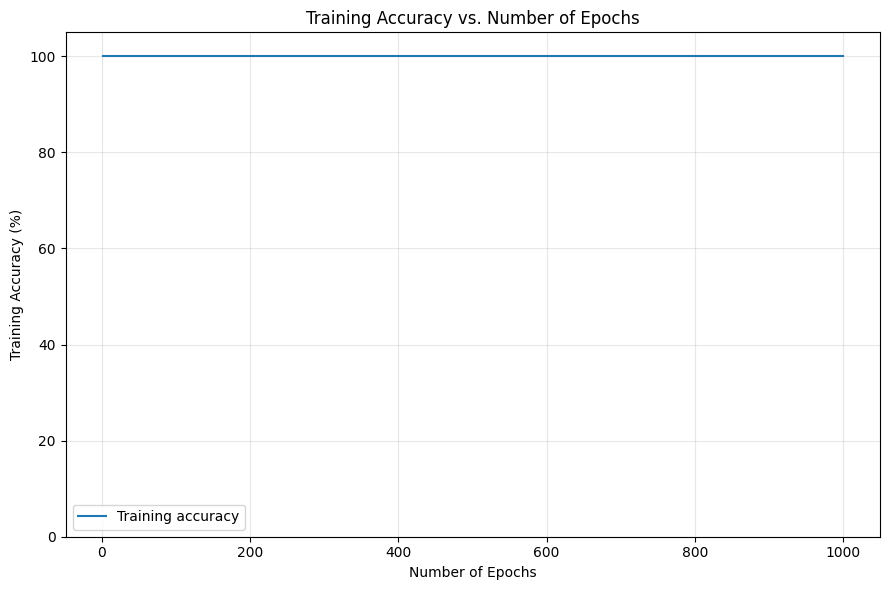

In [ ]:
plt.figure(figsize=(9, 6))
plt.plot(
    range(1, epochs + 1),
    training_accuracies,
    label="Training accuracy"
)
plt.xlabel("Number of Epochs")
plt.ylabel("Training Accuracy (%)")
plt.title("Training Accuracy vs. Number of Epochs")
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### 10. Evaluate the trained model on the test set

In [ ]:
# Test data was not used to calculate gradients or update weights.
test_probabilities = predict_probability(X_test_bias, weights)
test_predictions = (test_probabilities >= 0.5).astype(int)

final_train_accuracy = calculate_accuracy(
    X_train_bias, y_train, weights
)
test_accuracy = np.mean(test_predictions == y_test) * 100

print(f"Final training accuracy: {final_train_accuracy:.2f}%")
print(f"Final test accuracy: {test_accuracy:.2f}%")

print("\nFinal trained parameters:")
print(f"Bias (w0): {weights[0]:.6f}")
print(f"Petal length weight (w1): {weights[1]:.6f}")
print(f"Petal width weight (w2): {weights[2]:.6f}")


Final training accuracy: 100.00%
Final test accuracy: 100.00%

Final trained parameters:
Bias (w0): 0.417202
Petal length weight (w1): 2.835236
Petal width weight (w2): 2.839840
